# Le vrai prix de la ville : l'écart de prix selon la distance, à biens comparables

Le notebook d'exploration décrit les prix par tranche de distance et montre que les comparaisons brutes sont faussées par la localisation des ventes. Ici, on compare des ventes **comparables** (même commune, même année, même taille de logement) et on donne pour chaque résultat principal un **intervalle de confiance**. Les calculs restent simples (corrélations, différences de médianes), sans modèle économétrique.

Ce travail décrit des écarts de prix. Il ne mesure pas l'effet causal d'une station sur le prix.

## 1. Principe, hypothèses et mesure de l'incertitude

**Comparer des biens comparables.** Comparer directement les prix près et loin des stations est trompeur, car les stations sont plus nombreuses dans les communes chères. On neutralise donc la commune, l'année et la taille du logement par construction :

- le **prix relatif** d'une vente est son écart (en %) au prix médian de sa commune la même année ;
- une **cellule** regroupe les ventes d'une même commune, d'une même année et d'une même classe de surface (moins de 30 m², 30-50, 50-80, plus de 80). Dans une cellule, la commune, l'année et la taille sont fixées. Le quartier, l'étage et l'état du logement peuvent encore différer, car le DVF ne les renseigne pas ;
- les résultats des cellules sont ensuite résumés : moyenne pondérée par le nombre de ventes, médiane des cellules, part de cellules où l'écart est positif.

Les 1 % de prix les plus bas et les plus hauts de chaque zone sont écartés. Seules les stations de **métro et de RER** sont prises en compte : un logement proche d'un tramway ou d'une gare Transilien, mais loin du métro et du RER, est compté comme « loin ».

**Hypothèses de départ.** Elles sont posées avant les calculs et reprises dans la conclusion :

- **H1** : à biens comparables, le prix baisse quand la distance à la station augmente ;
- **H2** : à très courte distance (moins de 100 m), le prix est plus bas, à cause des nuisances (bruit, affluence) ;
- **H3** : l'écart entre biens proches et biens éloignés est plus marqué en petite couronne qu'à Paris, où le réseau est dense et où presque tout le monde habite près d'une station.

**Incertitude.** Chaque résultat principal est accompagné d'un intervalle de confiance à 95 % obtenu par **bootstrap par commune** : on tire 1 000 fois, avec remise, les communes de chaque zone, et on recalcule le résultat sur les cellules de ces communes. Tirer les communes plutôt que les ventes tient compte du fait que les ventes d'une même commune se ressemblent. Ces intervalles ne couvrent que l'aléa d'échantillonnage, pas les biais (composition des quartiers, qualité des biens). À Paris, ils reposent sur peu d'arrondissements, et sont donc larges.

In [1]:
from pathlib import Path
import sys

# Retrouver automatiquement la racine du dépôt depuis le dossier du notebook
CWD = Path.cwd().resolve()
ROOT = next((p for p in (CWD, *CWD.parents) if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError(f"Impossible de trouver pyproject.toml depuis {CWD}")

SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("Racine du projet trouvée :", ROOT.name)

Racine du projet trouvée : Projet_Data_2A_S1


In [2]:
import pandas as pd
from IPython.display import display

from vrai_prix import analysis as A
from vrai_prix import visualization as V

V.style()

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

### Vérification des données nécessaires

Ce notebook lit `data/processed/dvf-stations/dvf_appartements_stations.parquet` et, pour l'étude de cas, `data/raw/stations/emplacement_gares_idfm.geojson`. Ces fichiers sont fournis avec le projet. S'ils manquent, les régénérer depuis la racine du projet :

```bash
python -m vrai_prix.dvf
python -m vrai_prix.stations
```

Ces commandes ne retéléchargent pas les fichiers déjà présents dans `data/raw/`.

In [3]:
df = A.charger_donnees()
d = A.preparer(df)
print(f"{len(d):,} ventes utilisées sur {len(df):,}".replace(",", " "))

313 546 ventes utilisées sur 319 947


## 2. Corrélation entre distance et prix

La corrélation de Spearman compare les rangs (elle est peu sensible aux valeurs extrêmes), celle de Pearson mesure une liaison linéaire. Une valeur négative veut dire que le prix baisse quand la distance augmente. Elle va de −1 à 1, et une valeur proche de 0 indique une liaison faible.

On la calcule sur le prix brut, puis sur le prix relatif à la commune : la différence entre les deux montre ce qui vient du lieu.

In [4]:
A.sauver(A.correlations(d), "correlations_distance_prix.csv", index=False)

,zone,n,spearman_prix,pearson_prix,spearman_prix_relatif,pearson_prix_relatif
0,Ensemble,313546,-0.57,-0.46,-0.04,-0.04
1,Paris,140376,-0.05,-0.06,-0.01,-0.02
2,Petite couronne,173170,-0.25,-0.23,-0.06,-0.04


In [5]:
A.sauver(A.correlations(d, par="annee"), "correlations_par_annee.csv", index=False)

,zone,n,annee,spearman_prix,pearson_prix,spearman_prix_relatif,pearson_prix_relatif
0,Ensemble,70246,2021,-0.60,-0.49,-0.04,-0.03
1,Ensemble,73307,2022,-0.58,-0.48,-0.04,-0.04
2,Ensemble,57675,2023,-0.57,-0.47,-0.04,-0.03
3,Ensemble,51281,2024,-0.56,-0.45,-0.04,-0.03
4,Ensemble,61037,2025,-0.56,-0.45,-0.04,-0.04
5,Paris,29869,2021,-0.05,-0.06,-0.02,-0.02
6,Paris,32496,2022,-0.05,-0.05,-0.01,-0.02
7,Paris,26315,2023,-0.05,-0.06,-0.02,-0.02
8,Paris,23909,2024,-0.06,-0.07,-0.02,-0.02
9,Paris,27787,2025,-0.05,-0.06,-0.00,-0.01


Pris ensemble, le prix et la distance sont nettement corrélés négativement : Spearman −0,57 sur toute la période, entre −0,60 et −0,56 selon l'année, et Pearson autour de −0,45 à −0,49. Cette corrélation vient surtout de la différence entre Paris et la petite couronne : Paris est plus cher et ses ventes sont plus proches des stations. Dans chaque zone, elle est bien plus faible : environ −0,05 à Paris et −0,25 en petite couronne (Spearman, prix brut).

Avec le prix relatif à la commune, la corrélation tombe presque à zéro partout (entre 0 et −0,06). À l'intérieur d'une même commune, la distance à la station explique donc très peu les écarts de prix entre appartements.

Les valeurs sont stables d'une année à l'autre, avec seulement un léger recul de la corrélation d'ensemble (de −0,60 à −0,56).

Une corrélation faible ne veut pas dire qu'il n'y a aucun écart : elle résume la liaison sur toutes les distances, alors que l'écart semble surtout apparaître au-delà de 500-600 m (sections suivantes).

## 3. Variation du prix par tranche de 200 m

Prix médian dans chaque tranche de 200 m, et variation d'une tranche à la suivante, ramenée à 100 m. La colonne `variation_par_100m_eur` se lit : « 100 m plus loin, le prix médian change de x €/m² ». La colonne `variation_relatif_par_100m_pts` donne la même chose pour le prix relatif à la commune, en points de pourcentage.

,zone,tranche,n,prix_median,prix_relatif_median_pct,variation_eur,variation_pct,variation_par_100m_eur,variation_relatif_par_100m_pts
0,Paris,0-200,57341,"10,410.00",0.03,NaN,NaN,NaN,NaN
1,Paris,200-400,68168,"10,351.35",0.24,-58.65,-0.56,-29.32,0.11
2,Paris,400-600,13851,"9,864.86",-1.50,-486.49,-4.70,-243.24,-0.87
3,Paris,600-800,1016,"9,123.56",-5.07,-741.30,-7.51,-370.65,-1.79
4,Petite couronne,0-200,10896,"6,562.50",1.79,NaN,NaN,NaN,NaN
5,Petite couronne,200-400,30383,"6,346.15",2.14,-216.35,-3.30,-108.17,0.18
6,Petite couronne,400-600,32788,"6,120.77",0.97,-225.39,-3.55,-112.69,-0.58
7,Petite couronne,600-800,24435,"5,600.25",-1.17,-520.52,-8.50,-260.26,-1.07
8,Petite couronne,800-1000,18032,"5,222.22",-1.99,-378.03,-6.75,-189.01,-0.41
9,Petite couronne,1000-1200,13371,"4,951.47",0.00,-270.75,-5.18,-135.38,0.99


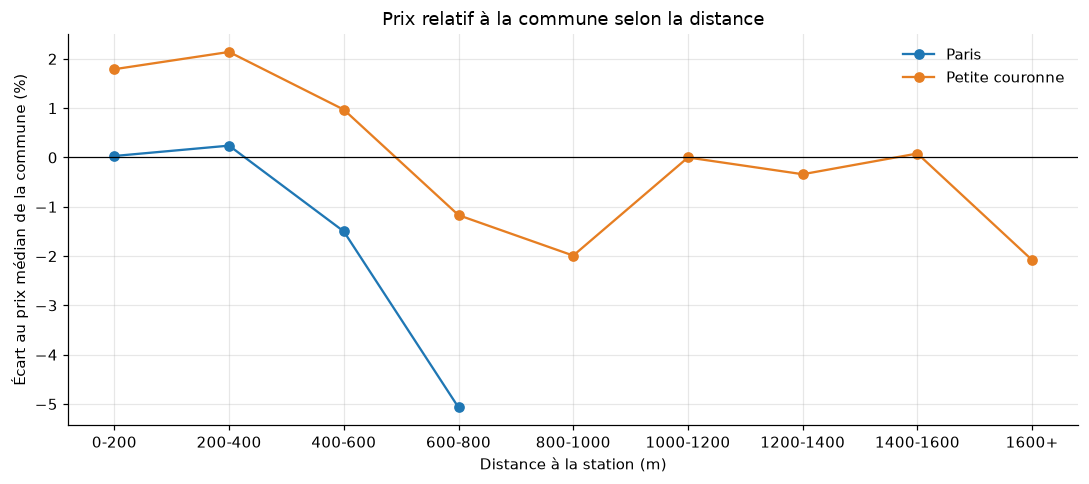

In [6]:
var = A.sauver(A.variation_par_tranche(d, largeur=200), "variation_par_tranche_200m.csv", index=False)
V.prix_relatif_tranches(var)
var

Dans les deux zones, le prix relatif à la commune est à peu près stable entre 0 et 400 m. À Paris, la tranche 0-200 m est au même niveau que 200-400 m (+0,0 % contre +0,2 %). En petite couronne, elle est à peine en dessous (+1,8 % contre +2,1 %). Ces différences de quelques dixièmes de point ne sont pas interprétables.

La baisse commence à 400-600 m. À Paris, elle est nette : −1,5 % à 400-600 m, puis environ −5 % à 600-800 m (1 016 ventes seulement). En petite couronne, elle est plus progressive : +1,0 % à 400-600 m, −1,2 % à 600-800 m et −2,0 % à 800-1 000 m.

Au-delà de 1 000 m, la courbe de la petite couronne remonte autour de zéro puis redescend à −2,1 % au-delà de 1 600 m. Cette irrégularité tient probablement à la composition des ventes (peu de communes à ces distances), pas à la distance. À Paris, il n'y a pas de tranche au-delà de 800 m, faute de ventes.

## 4. Écart à la tranche de référence, à biens comparables

Dans chaque cellule, on compare la médiane de chaque tranche à celle de la tranche 200-400 m, prise comme référence. La colonne `ecart_pct` est la moyenne pondérée sur les cellules, avec son intervalle de confiance à 95 % (`ic_bas_moyenne`, `ic_haut_moyenne`). La médiane des cellules a aussi son intervalle. `part_cellules_positives_%` indique si le résultat est partagé par la plupart des cellules ou porté par quelques-unes.

,zone,tranche,ecart_pct,ic_bas_moyenne,ic_haut_moyenne,ecart_median_cellules_pct,ic_bas_mediane,ic_haut_mediane,n_cellules,n_communes,part_cellules_positives_%,n_ventes
0,Paris,0-100,-0.88,-2.09,0.28,-1.37,-2.59,0.36,349.00,20.00,42.41,"13,907.00"
1,Paris,100-200,-0.25,-1.40,0.70,-0.79,-2.08,0.34,400.00,20.00,43.00,"43,071.00"
2,Paris,400-600,-1.80,-3.24,-0.20,-1.28,-2.69,-0.03,235.00,14.00,39.57,"13,517.00"
3,Paris,600-1000,-6.54,-17.10,-0.66,-3.60,-21.20,0.48,39.00,5.00,33.33,581.00
4,Petite couronne,0-100,-3.54,-7.77,0.58,-2.38,-4.25,1.94,34.00,7.00,29.41,431.00
5,Petite couronne,100-200,-0.78,-2.13,0.73,-0.01,-1.02,1.26,293.00,33.00,49.83,"5,681.00"
6,Petite couronne,400-600,-0.92,-2.42,0.73,-1.25,-2.13,0.31,667.00,64.00,44.38,"25,997.00"
7,Petite couronne,600-1000,-3.03,-6.21,0.16,-4.08,-6.01,-1.56,620.00,62.00,33.71,"27,193.00"


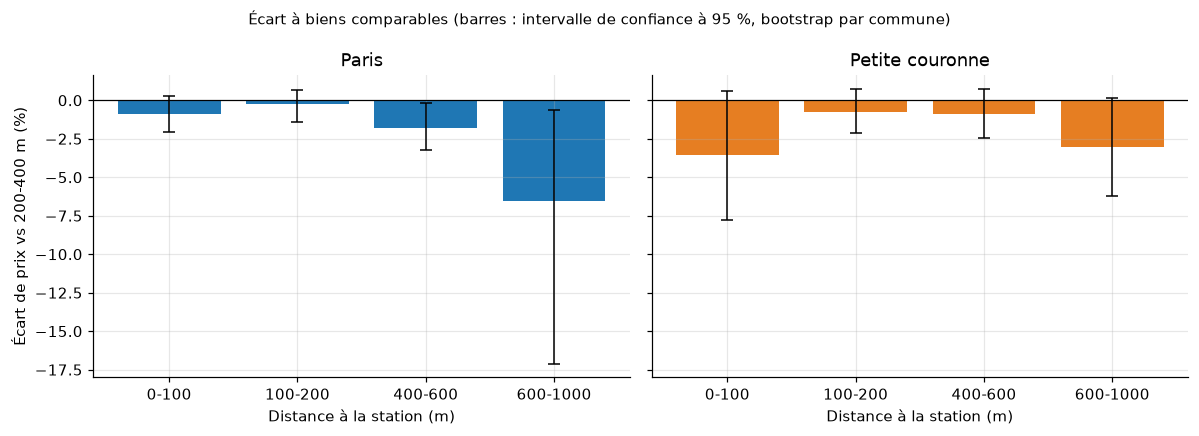

In [7]:
ecarts, tirages_ecarts = A.ic_ecarts(d)
A.sauver(ecarts, "ecarts_stratifies.csv", index=False)
V.ecarts_stratifies_barres(ecarts)
ecarts

L'écart est-il plus fort à Paris qu'en petite couronne au-delà de 600 m ? On calcule la différence entre les deux zones et son intervalle à partir des mêmes tirages.

In [8]:
diff_600_1000 = A.sauver(A.difference_zones(tirages_ecarts, ecarts, {"tranche": "600-1000"}),
                         "difference_zones_600_1000.csv", index=False)
diff_600_1000

,statistique,Paris,Petite couronne,difference_Paris_moins_PC,ic_bas,ic_haut
0,moyenne pondérée,-6.54,-3.03,-3.51,-14.28,3.05
1,médiane des cellules,-3.60,-4.08,0.48,-17.38,4.25


**Au-delà de 600 m, le prix est plus bas que dans la référence.** En petite couronne, l'écart à 600-1 000 m est de −3,0 % en moyenne pondérée (IC 95 % : −6,2 à +0,2) et de −4,1 % pour la cellule médiane (IC : −6,0 à −1,6). Seule une cellule sur trois (34 %) est au-dessus de la référence. À Paris, l'écart est de −6,5 % (IC : −17,1 à −0,7), mais il repose sur 39 cellules issues de 5 arrondissements seulement. La baisse commence dès 400-600 m, mais elle y est faible : −1,8 % à Paris (IC : −3,2 à −0,2) et −0,9 % en petite couronne (IC : −2,4 à +0,7).

**L'écart n'est pas plus fort à Paris de façon démontrée.** Le −6,5 % parisien est une moyenne pondérée tirée par quelques arrondissements. La cellule médiane donne −3,6 % à Paris et −4,1 % en petite couronne : la différence (+0,5 point) a un intervalle de −17,4 à +4,3 points. Les deux zones ne sont donc pas distinguables.

**À courte distance, aucune tranche ne se distingue de la référence.** Les tranches 0-100 m et 100-200 m sont légèrement en dessous de 200-400 m (−0,9 % et −0,3 % à Paris, −0,8 % à 100-200 m en petite couronne), mais tous les intervalles contiennent zéro, et 42 % à 50 % des cellules seulement sont positives. Il n'y a donc pas de « distance la plus valorisée » identifiable entre 0 et 400 m : le prix forme un **plateau**.

**La décote à moins de 100 m en petite couronne est fragile.** Elle vaut −3,5 % (IC : −7,8 à +0,6), mais ne porte que sur 34 cellules dans 7 communes (431 ventes), et l'intervalle contient zéro. Les coordonnées sont celles du centre de la parcelle, ce qui ajoute du bruit à si courte distance.

## 5. Prime de proximité : biens proches contre biens éloignés

Même méthode avec deux groupes : ventes à moins de 300 m d'une station contre ventes à 600 m ou plus. La prime est `médiane proche / médiane loin − 1`, calculée dans chaque cellule, puis moyennée avec pour poids le plus petit des deux effectifs.

In [9]:
prime, tirages_prime = A.ic_prime(d)
A.sauver(prime, "prime_stratifiee.csv", index=False)
prime

,zone,prime_%,ic_bas_moyenne,ic_haut_moyenne,mediane_cellules_%,ic_bas_mediane,ic_haut_mediane,n_cellules,n_communes
0,Paris,8.90,1.13,20.51,6.91,-0.59,25.08,39.00,5.00
1,Petite couronne,7.81,3.51,12.66,4.89,1.75,7.67,582.00,59.00


,zone,annee,prime_%,ic_bas_moyenne,ic_haut_moyenne,mediane_cellules_%,ic_bas_mediane,ic_haut_mediane,n_cellules,n_communes
0,Paris,2021,13.86,2.88,29.13,9.60,-7.13,30.15,10.00,5.00
1,Paris,2022,11.96,-0.09,23.36,5.98,-1.75,28.30,10.00,5.00
2,Paris,2023,2.72,-2.18,4.67,0.45,-2.18,5.10,5.00,3.00
3,Paris,2024,7.41,-0.28,16.49,8.85,-4.21,26.58,6.00,4.00
4,Paris,2025,2.87,-5.27,15.29,3.95,-0.59,10.57,8.00,4.00
5,Petite couronne,2021,7.42,2.91,12.44,4.70,1.06,6.62,129.00,51.00
6,Petite couronne,2022,7.99,3.94,12.65,5.76,2.26,8.76,131.00,51.00
7,Petite couronne,2023,7.77,2.76,12.70,2.90,-0.73,9.17,104.00,43.00
8,Petite couronne,2024,8.94,4.15,14.16,6.08,1.75,10.07,105.00,40.00
9,Petite couronne,2025,7.22,2.91,11.79,4.94,2.57,8.38,113.00,47.00


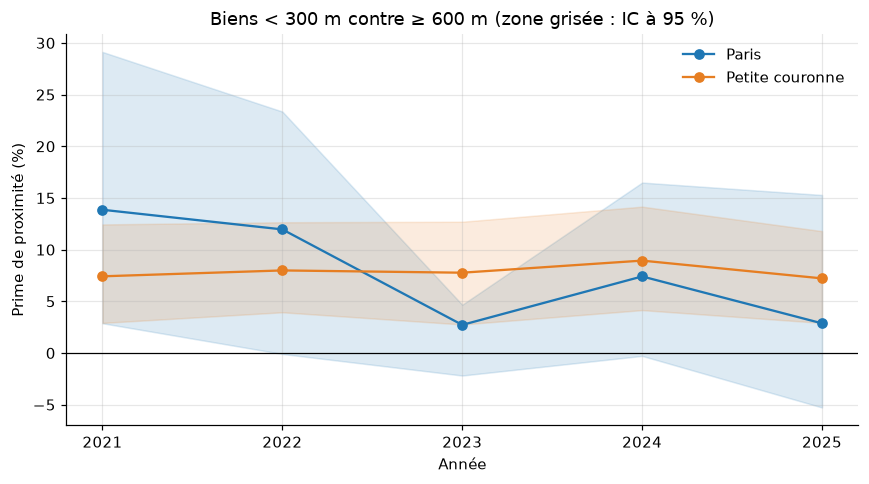

In [10]:
prime_annee, _ = A.ic_prime(d, par_annee=True)
A.sauver(prime_annee, "prime_stratifiee_par_annee.csv", index=False)
V.prime_stratifiee_annee(prime_annee)
prime_annee

La prime est-elle plus forte en petite couronne qu'à Paris (hypothèse H3) ?

In [11]:
diff_prime = A.sauver(A.difference_zones(tirages_prime, prime), "difference_zones_prime.csv", index=False)
diff_prime

,statistique,Paris,Petite couronne,difference_Paris_moins_PC,ic_bas,ic_haut
0,moyenne pondérée,8.90,7.81,1.09,-8.01,14.27
1,médiane des cellules,6.91,4.89,2.02,-6.60,21.05


**En petite couronne**, les biens à moins de 300 m d'une station se vendent en moyenne **7,8 % plus cher** que ceux à 600 m ou plus, à commune, année et classe de surface comparables (IC 95 % : 3,5 à 12,7 %, 582 cellules dans 59 communes). La cellule médiane donne un écart plus faible, **4,9 %** (IC : 1,8 à 7,7 %), car quelques cellules à gros écarts tirent la moyenne vers le haut. Deux cellules sur trois (66 %) ont une prime positive. D'une année à l'autre, la prime varie entre 7,2 % et 8,9 %, et chaque intervalle annuel exclut zéro : le résultat est stable.

**À Paris**, la prime est estimée à 8,9 %, mais avec un intervalle très large (1,1 à 20,5 %), car elle repose sur 39 cellules issues de 5 arrondissements. Par année, elle passe de 13,9 % en 2021 à 2,7 % en 2023, 7,4 % en 2024 et 2,9 % en 2025. Les intervalles annuels se chevauchent largement et seul celui de 2021 exclut zéro : on ne peut pas conclure à une baisse de la prime parisienne.

**H3 n'est pas confirmée.** L'estimation parisienne (8,9 %) est même un peu plus haute que celle de la petite couronne (7,8 %), mais la différence (+1,1 point) a un intervalle de −8,0 à +14,3 points. Les données ne permettent pas de dire quelle zone a la prime la plus forte.

Ce résultat découle de la section 4 : le prix est à peu près stable à moins de 400 m et baisse au-delà de 600 m. La prime proche/loin vient donc de **la baisse au-delà de 600 m**, pas d'un bonus particulier pour les biens collés aux stations.

## 6. Robustesse

Le résultat tient-il quand on change les seuils de proximité, le nombre minimal de ventes par groupe, ou quand on garde les prix extrêmes ?

In [12]:
A.sauver(A.robustesse_prime(df), "robustesse_prime_stratifiee.csv", index=False)

,specification,zone,prime_%,mediane_cellules_%,q25_%,q75_%,part_cellules_positives_%,n_cellules,n_communes
0,"référence : <300 m vs ≥600 m, 10 ventes min.",Paris,8.90,6.91,-1.21,15.40,69.23,39.00,5.00
1,"référence : <300 m vs ≥600 m, 10 ventes min.",Petite couronne,7.81,4.89,-2.90,13.99,66.15,582.00,59.00
2,<200 m vs ≥500 m,Paris,4.57,3.84,0.40,10.14,77.60,125.00,9.00
3,<200 m vs ≥500 m,Petite couronne,5.42,5.04,-2.77,12.08,66.86,344.00,44.00
4,<400 m vs ≥800 m,Petite couronne,8.58,4.82,-2.98,15.83,66.84,570.00,62.00
5,20 ventes min. par groupe,Paris,3.07,-4.21,-7.36,12.07,40.00,5.00,3.00
6,20 ventes min. par groupe,Petite couronne,8.24,5.44,-0.69,12.82,71.43,322.00,39.00
7,5 ventes min. par groupe,Paris,8.55,7.07,-0.78,14.16,72.22,90.00,6.00
8,5 ventes min. par groupe,Petite couronne,7.55,4.54,-3.81,14.89,64.58,895.00,73.00
9,sans écarter les prix extrêmes,Paris,9.17,6.88,-0.91,17.96,70.00,40.00,6.00


**En petite couronne**, la prime reste positive et du même ordre dans toutes les spécifications : de 5,4 % à 8,6 % en moyenne pondérée, avec 65 % à 71 % de cellules positives et 322 à 895 cellules. Toutes ces valeurs sont dans l'intervalle de confiance de la spécification de référence (3,5 à 12,7 %) : les différences entre spécifications sont de l'ordre de l'incertitude. La prime est la plus faible quand on compare les biens à moins de 200 m à ceux à 500 m ou plus (5,4 %), ce qui est logique : les deux groupes sont moins éloignés l'un de l'autre. Garder les prix extrêmes ne change presque rien (7,8 % dans les deux cas : 7,76 % contre 7,81 %).

**À Paris**, la prime est positive dans toutes les spécifications calculables, mais sa taille varie beaucoup : de 3,1 % à 9,2 %. Elle repose sur peu de cellules : 39 dans la spécification de référence. Avec 20 ventes minimum par groupe, il ne reste que 5 cellules dans 3 arrondissements, et la prime tombe à 3,1 % avec une cellule médiane négative (−4,2 %). La comparaison 400 m contre 800 m est impossible à Paris, faute de ventes éloignées. On peut dire que le signe est le plus souvent positif, pas en donner la taille.

**Chiffre à retenir.** Partout, la moyenne pondérée est supérieure à la médiane des cellules (7,8 % contre 4,9 % en petite couronne). Le résultat le plus défendable est donc une prime d'environ **8 % en petite couronne (IC 95 % : 3,5 à 12,7 %)**, avec un écart typique par cellule d'environ **5 % (IC : 1,8 à 7,7 %)**. Les variantes de 5 à 9 % obtenues en changeant les seuils sont toutes compatibles avec ce chiffre.

## 7. Étude de cas : les prolongements des lignes 11 et 14 (juin 2024)

En juin 2024, la ligne 11 a été prolongée jusqu'à Rosny-Bois-Perrier et la ligne 14 jusqu'à Saint-Denis-Pleyel au nord et jusqu'à l'aéroport d'Orly au sud. On observe ce qui se passe quand un quartier **gagne** une station, en suivant les mêmes quartiers avant et après l'ouverture.

Deux groupes de ventes, définis par la position du logement (et non par la date de la vente) :

- **desservi** : à moins de 600 m d'une nouvelle station et à plus de 800 m de toute station existant avant l'ouverture. Les nouvelles stations implantées là où une autre ligne passait déjà (Maison Blanche, Saint-Denis-Pleyel, Rosny-Bois-Perrier) n'apportent donc pas de quartier desservi ;
- **témoin** : ventes des mêmes communes situées à plus de 1,2 km de toute nouvelle station.

Les deux groupes n'ont pas le même niveau de prix. On compare donc leur **évolution** : prix médian au m² en base 100 en 2021.

,n Desservi en 2024,prix_median Desservi en 2024,indice Desservi en 2024,n Témoin,prix_median Témoin,indice Témoin,ecart_indices
annee,,,,,,,
2021,530,"4,416.00",100.00,2278,"5,295.00",100.00,0.00
2022,494,"4,667.00",105.70,2400,"5,470.00",103.30,2.40
2023,370,"4,763.00",107.90,1789,"5,171.00",97.70,10.20
2024,366,"4,175.00",94.50,1495,"4,804.00",90.70,3.80
2025,427,"4,808.00",108.90,1780,"4,900.00",92.50,16.40


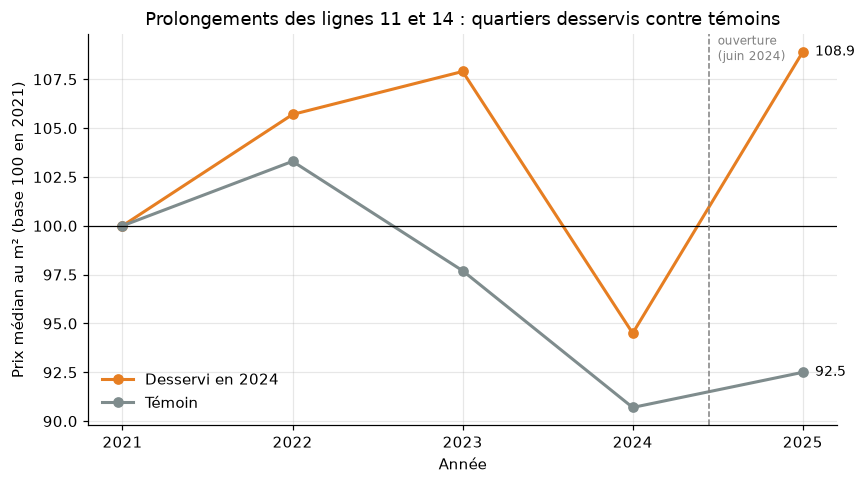

In [13]:
d_prol = A.distances_prolongements(df)
g_prol = A.groupes_prolongements(d_prol)
prol = A.sauver(A.evolution_prolongements(g_prol), "prolongements_l11_l14.csv")
V.evolution_prolongements(prol)
prol

### 7.1. Les deux groupes sont-ils comparables ?

In [14]:
profil_prol = A.sauver(A.profil_groupes_prolongements(g_prol), "profil_groupes_prolongements.csv")
profil_prol.T

groupe,Desservi en 2024,Témoin
ventes,2187,9742
communes,13,13
commune_principale,Romainville,Montreuil
ventes_commune_principale,731,3989
part_commune_principale_%,33.40,40.90
dist_mediane_station_avant_2024_m,"1,449.40",518.80
surface_mediane_m2,59.00,51.00
prix_median_2021,"4,416.10","5,295.40"


**Non.** Les deux groupes diffèrent sur plusieurs points :

- **la desserte avant 2024** : la distance médiane à une station existante était de 1 449 m pour les quartiers desservis, contre 519 m pour les témoins. Les quartiers desservis étaient mal desservis, les témoins le sont bien. Ce sont des quartiers de nature différente ;
- **le niveau de prix** : 4 416 €/m² en 2021 pour les desservis, contre 5 295 €/m² pour les témoins (−17 %). Un quartier moins cher peut rattraper son retard pour d'autres raisons que le métro ;
- **la concentration** : Romainville fournit à elle seule 731 des 2 187 ventes desservies (33 %), et Montreuil 41 % des ventes témoins. Une seule commune pèse donc lourd dans chaque groupe.

L'écart d'évolution entre les deux groupes ne peut donc pas être attribué au seul métro.

### 7.2. Quelle précision pour l'écart d'indices ?

On calcule l'intervalle de confiance à 95 % de l'écart d'indices de deux façons :

- **par commune** (prudent) : on tire les 13 communes avec remise. Avec si peu de communes, l'intervalle est large ;
- **par vente** (optimiste) : on tire les ventes dans chaque groupe et chaque année, comme si elles étaient indépendantes.

On refait aussi le calcul **à surface constante** : le prix de chaque groupe est la moyenne des médianes par classe de surface, avec des parts fixes. Cela vérifie que l'écart ne vient pas d'un changement de taille des logements vendus.

In [15]:
ic_prol = pd.concat({
    "par commune": A.ic_prolongements(g_prol, par="commune"),
    "par vente": A.ic_prolongements(g_prol, par="vente"),
    "par vente, surface constante": A.ic_prolongements(g_prol, par="vente", surface_constante=True),
    "par commune, surface constante": A.ic_prolongements(g_prol, par="commune", surface_constante=True),
}, axis=1)
A.sauver(ic_prol, "ic_prolongements.csv")
ic_prol

par commune                                    par vente         \
      ecart_indices ic_bas ic_haut significatif_5% ecart_indices ic_bas   
annee                                                                     
2021           0.00   0.00    0.00           False          0.00   0.00   
2022           2.40  -7.10   15.10           False          2.40  -4.50   
2023          10.20  -3.30   25.50           False         10.20   2.10   
2024           3.80  -5.90   15.50           False          3.80  -2.90   
2025          16.40   1.20   30.00            True         16.40   9.40   

                              par vente, surface constante                 \
      ic_haut significatif_5%                ecart_indices ic_bas ic_haut   
annee                                                                       
2021     0.00           False                         0.00   0.00    0.00   
2022    11.00           False                         2.10  -4.90    8.20   
2023    18.70            True                        13.50   6.20   18.80   
2024    11.70           False                         3.30  -2.30    9.10   
2025    24.30            True                        14.60   7.90   20.10   

                      par commune, surface constante                 \
      significatif_5%                  ecart_indices ic_bas ic_haut   
annee                                                                 
2021            False                           0.00   0.00    0.00   
2022            False                           2.10  -6.30   10.50   
2023             True                          13.50   0.70   22.60   
2024            False                           3.30  -6.60   14.00   
2025             True                          14.60   1.10   22.90   

                       
      significatif_5%  
annee                  
2021            False  
2022            False  
2023             True  
2024            False  
2025             True

In [16]:
specs = [(600, 800, 1200), (400, 800, 1200), (800, 800, 1200), (600, 600, 1200), (600, 800, 1500)]
lignes = []
for rayon, avant, loin in specs:
    t = A.evolution_prolongements(A.groupes_prolongements(d_prol, rayon, avant, loin))
    lignes.append({"rayon_m": rayon, "sans_station_avant_m": avant, "temoin_au_dela_m": loin,
                   "ventes_desservies": int(t["n Desservi en 2024"].sum()),
                   **{f"ecart_{a}": t.loc[a, "ecart_indices"] for a in t.index}})
A.sauver(pd.DataFrame(lignes), "robustesse_prolongements.csv", index=False)

,rayon_m,sans_station_avant_m,temoin_au_dela_m,ventes_desservies,ecart_2021,ecart_2022,ecart_2023,ecart_2024,ecart_2025
0,600,800,1200,2187,0.00,2.40,10.20,3.80,16.40
1,400,800,1200,1333,0.00,-1.60,9.80,3.20,12.50
2,800,800,1200,2888,0.00,4.50,9.70,6.30,15.50
3,600,600,1200,2411,0.00,3.60,10.90,3.60,14.50
4,600,800,1500,2187,0.00,2.30,8.90,3.20,15.60


### 7.3. Ce qu'on peut dire, et ce qu'on ne peut pas dire

**Ce qui est solide.** De 2021 à 2025, le prix médian des quartiers desservis augmente d'environ 9 % (indice 108,9), alors que celui des quartiers témoins baisse d'environ 7 % (indice 92,5). L'écart atteint **16,4 points en 2025**. Dans la spécification de base, c'est la seule année où l'intervalle exclut zéro avec les deux méthodes : de 9,4 à 24,3 points par vente, de 1,2 à 30,0 points par commune. Il reste entre 12,5 et 16,4 points quand on change les seuils de distance, et vaut 14,6 points à surface constante.

**L'anticipation n'est pas démontrée.** En 2023, avant l'ouverture, l'écart est déjà de +10,2 points. Son intervalle exclut zéro par vente (2,1 à 18,7), mais pas par commune (−3,3 à 25,5). À surface constante (+13,5 points), il exclut zéro avec les deux méthodes, de justesse par commune (0,7 à 22,6). Le signal dépend donc de la méthode, et les intervalles de 2022 (+2,4) et de 2023 se chevauchent largement. Surtout, même un écart certain avant l'ouverture ne prouverait pas une anticipation : il peut aussi vouloir dire que les deux groupes suivaient déjà des trajectoires différentes avant le métro, ce qui est plausible vu leurs différences (section 7.1). Les données ne permettent pas de trancher entre ces deux lectures.

**2024 n'est pas une simple « année de transition ».** Un mélange de ventes conclues avant et après juin donnerait un niveau intermédiaire entre 2023 et 2025. On observe au contraire un creux, deux fois plus profond chez les desservis (−13,4 points d'indice entre 2023 et 2024) que chez les témoins (−7,0 points). Ce creux n'a pas d'explication claire dans nos données. Avec environ 370 ventes desservies cette année-là, il peut aussi relever du bruit (IC de 2024 par vente : −2,9 à +11,7).

**Conclusion de l'étude de cas.** À fin 2025, les quartiers qui ont gagné une station ont gagné environ 16 points sur les témoins de leurs communes (IC 95 % : 9 à 24 points si l'on traite les ventes comme indépendantes, 1 à 30 points en tenant compte des communes). Comme les groupes ne sont pas comparables (quartiers mal desservis et moins chers au départ, poids de Romainville), cet écart n'a pas de cause identifiée : il peut refléter l'arrivée du métro, un rattrapage de quartiers moins chers, ou d'autres transformations urbaines (rénovation, programmes neufs). Les ventes en VEFA sont en outre exclues de la base.

## 8. Conclusion et limites

À commune, année et taille de logement comparables, les appartements proches d'une station de métro ou de RER se vendent un peu plus cher que les appartements éloignés. L'écart est modeste, et il vient de la **baisse du prix au-delà de 600 m**, pas d'un bonus près des stations.

- **La corrélation globale est trompeuse.** Pris ensemble, le prix et la distance sont fortement corrélés (Spearman −0,57), mais surtout parce que Paris est plus cher et mieux desservi. Rapportée au prix de la commune, la corrélation tombe presque à zéro (entre 0 et −0,06).
- **Un plateau jusqu'à 400 m, puis une baisse.** À biens comparables, aucune tranche entre 0 et 400 m ne se distingue de la référence 200-400 m : les écarts (de 0 à −0,9 %) sont dans la marge d'erreur. Au-delà de 600 m, le prix est plus bas : −3,0 % en petite couronne (IC : −6,2 à +0,2) et −4,1 % pour la cellule médiane (IC : −6,0 à −1,6) ; −6,5 % à Paris (IC : −17,1 à −0,7), sur 5 arrondissements seulement.
- **Une prime de proximité d'environ 8 % en petite couronne.** Les biens à moins de 300 m se vendent en moyenne 7,8 % plus cher que ceux à 600 m ou plus (IC : 3,5 à 12,7 %), et la cellule typique 4,9 % plus cher (IC : 1,8 à 7,7 %). Ce chiffre est stable de 2021 à 2025 et selon les seuils. À Paris, l'estimation est de 8,9 %, mais avec un intervalle de 1,1 à 20,5 %.
- **Étude de cas des lignes 11 et 14.** À fin 2025, les quartiers qui ont gagné une station ont gagné environ 16 points sur leurs témoins (IC : 9 à 24 points par vente, 1 à 30 par commune). Comme les deux groupes ne sont pas comparables, cet écart n'a pas de cause identifiée, et aucune anticipation avant l'ouverture n'est démontrée.

**Ce que disent nos hypothèses.**

- **H1** (le prix baisse avec l'éloignement) est **confirmée au-delà de 600 m** en petite couronne, de façon plus incertaine à Paris. Elle ne l'est **pas entre 0 et 400 m**, où le prix est plat.
- **H2** (décote à très courte distance) est **suggérée en petite couronne mais non établie** (−3,5 %, IC : −7,8 à +0,6, sur 7 communes). Elle n'apparaît pas à Paris (−0,9 %, IC : −2,1 à +0,3).
- **H3** (prime plus forte en petite couronne) **n'est pas confirmée** : l'estimation parisienne est même plus haute (8,9 % contre 7,8 %), et la différence entre zones (+1,1 point, IC : −8,0 à +14,3) n'est pas distinguable de zéro.

**Limites.**

- Ces calculs décrivent des associations, pas des effets causaux : les stations sont implantées dans des zones déjà denses et recherchées.
- Une cellule rapproche des biens de même commune, même année et même classe de surface, mais pas de même étage, état ou quartier, que le DVF ne renseigne pas. L'échelle de la commune est large, surtout en petite couronne.
- Seules les stations de métro et de RER sont prises en compte. En petite couronne, un logement proche d'un tramway ou d'une gare Transilien est compté « loin », ce qui tend à atténuer les écarts.
- Les intervalles de confiance ne couvrent que l'aléa d'échantillonnage. À Paris, ils reposent sur 5 arrondissements pour les comparaisons proche/loin. Presque aucune vente parisienne ne se situe à plus de 800 m d'une station.
- Les coordonnées sont celles du centre de la parcelle, ce qui ajoute du bruit aux très courtes distances (moins de 100 m).
- La distance est mesurée à vol d'oiseau, pas en temps de marche, et la qualité du service (fréquence, nombre de lignes, fréquentation) n'est pas prise en compte.
- Les moyennes pondérées sont plus élevées que les médianes des cellules : quelques cellules à gros écarts tirent les moyennes vers le haut. L'écart est donc hétérogène d'une commune à l'autre.
- La base ne contient que les reventes d'appartements seuls (les VEFA sont exclues), et ni les parcs, ni les axes routiers, ni les équipements ne sont pris en compte.